In [39]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md




/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000000/00000000.arcs
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000000/00000000.nodes
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000000/00000000.route
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000000/00000000.track
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000007/00000007.arcs
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000007/00000007.nodes
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000007/00000007.route
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000007/00000007.track
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000009/00000009.arcs
/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000009/00000009.nodes
/kaggle/input/datasets/

In [40]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root[len("/kaggle/input"):].count(os.sep)
    if depth > 2:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{root}/")
    for f in files[:5]:
        print(f"{indent}  ├── {f}")

/kaggle/input/
  /kaggle/input/datasets/
    /kaggle/input/datasets/shristisaha903/


In [41]:
import os
for p in sorted(os.listdir("/kaggle/input/datasets/shristisaha903")):
    full = os.path.join("/kaggle/input/datasets/shristisaha903", p)
    print(p, "→", "DIR" if os.path.isdir(full) else "FILE")

dataset → DIR


In [42]:
BASE_DIR = "/kaggle/input/datasets/shristisaha903/dataset"   # replace with the actual name

In [43]:
import glob
tracks = glob.glob(os.path.join(BASE_DIR, "**", "*.track"), recursive=True)
print("Found", len(tracks), ".track files")
print(tracks[:3])

Found 90 .track files
['/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000000/00000000.track', '/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000007/00000007.track', '/kaggle/input/datasets/shristisaha903/dataset/Student folder/student_test/00000009/00000009.track']


In [44]:
print(os.listdir(BASE_DIR))

['Student folder']


In [45]:
import os

# Look inside the "Student folder"
base_student = os.path.join(BASE_DIR, "Student folder")
print("Inside 'Student folder':", os.listdir(base_student))

# Let's check the structure of one specific trip to see the exact file names
sample_trip_dir = os.path.join(base_student, "student_test", "00000000")
print("\nFiles inside a single trip folder:", os.listdir(sample_trip_dir))

Inside 'Student folder': ['student_test', 'train']

Files inside a single trip folder: ['00000000.arcs', '00000000.nodes', '00000000.route', '00000000.track']


In [46]:
import pandas as pd
import numpy as np

def load_track(path):
    # whitespace-separated: lon, lat, timestamp_seconds, no header
    return pd.read_csv(path, sep=r"\s+", header=None, names=["lon", "lat", "t"])

def load_nodes(path):
    df = pd.read_csv(path, sep=r"\s+", header=None, names=["lon", "lat"])
    df["node_id"] = df.index
    return df

def load_arcs(path):
    df = pd.read_csv(path, sep=r"\s+", header=None, names=["from_node", "to_node"])
    df["arc_id"] = df.index
    return df

def load_route(path):
    return pd.read_csv(path, sep=r"\s+", header=None, names=["arc_id"])

def get_partition(path):
    # Extracts 'train', 'student_test', or 'evaluator_test' based on the folder path
    if "train" in path.lower(): return "train"
    if "student" in path.lower(): return "student_test"
    if "evaluator" in path.lower(): return "evaluator_test"
    return "unknown"

In [47]:
import glob

files = glob.glob(os.path.join(BASE_DIR, "**", "*.track"), recursive=True)
rows = []

for trk_path in files:
    partition = get_partition(trk_path)
    
    # Use parent folder as trip ID (e.g., '00000000')
    trip_id = os.path.basename(os.path.dirname(trk_path))
    stem = os.path.splitext(trk_path)[0] # path without .track
    
    tr = load_track(trk_path)
    
    # Check for sibling files
    nodes_path = stem + ".nodes"
    arcs_path  = stem + ".arcs"
    route_path = stem + ".route"
    
    has_route = os.path.exists(route_path)
    n_nodes = len(load_nodes(nodes_path)) if os.path.exists(nodes_path) else np.nan
    n_arcs  = len(load_arcs(arcs_path))   if os.path.exists(arcs_path)  else np.nan
    
    # Calculate time gaps
    dt = tr.t.diff().dropna()
    
    rows.append({
        "partition": partition,
        "trip_id": trip_id,
        "n_gps": len(tr),
        "n_nodes": n_nodes,
        "n_arcs": n_arcs,
        "has_route": has_route,
        "dt_mean": dt.mean() if len(dt) else np.nan,
        "dt_max": dt.max() if len(dt) else np.nan,
    })

inv = pd.DataFrame(rows).sort_values(by=["partition", "trip_id"]).reset_index(drop=True)

# Show summary
print(inv.groupby("partition").size())
print("\nMissing values:")
print(inv.isna().sum())

# Save to working directory for the report
inv.to_csv("/kaggle/working/trip_inventory.csv", index=False)
inv.head()

partition
student_test    10
train           80
dtype: int64

Missing values:
partition    0
trip_id      0
n_gps        0
n_nodes      0
n_arcs       0
has_route    0
dt_mean      0
dt_max       0
dtype: int64


,partition,trip_id,n_gps,n_nodes,n_arcs,has_route,dt_mean,dt_max
0,student_test,00000000,2503,8542,18196,True,1.000400,2.0
1,student_test,00000007,1354,2061,4369,True,1.000000,1.0
2,student_test,00000009,1049,6745,13106,True,1.000954,2.0
3,student_test,00000040,2995,12945,27026,True,1.000000,1.0
4,student_test,00000052,262,1770,3577,True,1.015326,2.0


Fraction exactly 1s: 96.68%
Max gap: 153064.0 seconds


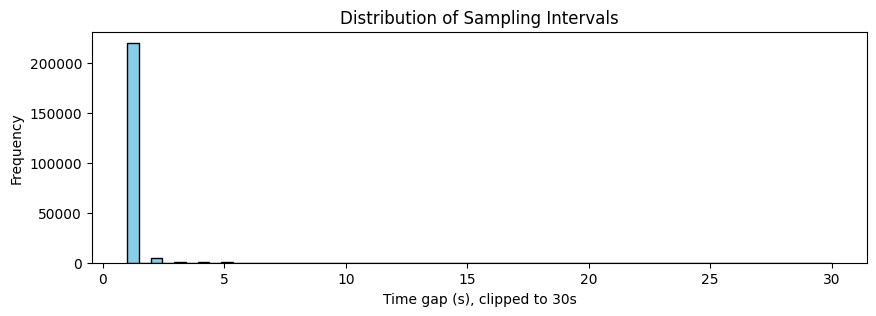

In [48]:
import matplotlib.pyplot as plt

all_dt = []
for trk_path in files:
    tr = load_track(trk_path)
    all_dt.append(tr.t.diff().dropna().values)
all_dt = np.concatenate(all_dt)
all_dt = all_dt[all_dt >= 0]

print(f"Fraction exactly 1s: {(all_dt == 1).mean():.2%}")
print(f"Max gap: {all_dt.max()} seconds")

plt.figure(figsize=(10, 3))
plt.hist(np.clip(all_dt, 0, 30), bins=60, color='skyblue', edgecolor='black')
plt.xlabel("Time gap (s), clipped to 30s")
plt.ylabel("Frequency")
plt.title("Distribution of Sampling Intervals")
plt.show()

In [49]:
import folium

# Use trip 00000000
stem = os.path.join(BASE_DIR, "Student folder", "student_test", "00000000", "00000000")
tr = load_track(stem + ".track")
nodes = load_nodes(stem + ".nodes")
arcs = load_arcs(stem + ".arcs")
route = load_route(stem + ".route")

# Create base map centered on the start of the trip
m = folium.Map(location=[tr.lat.iloc[0], tr.lon.iloc[0]], zoom_start=15)

# 1. Draw Raw GPS (Blue, every 20th point to prevent freezing)
for i in range(0, len(tr), 20):
    folium.CircleMarker(
        location=[tr.lat.iloc[i], tr.lon.iloc[i]], 
        radius=2, color="blue", fill=True, opacity=0.6
    ).add_to(m)

# 2. Draw Ground Truth Route (Green line)
node_lookup = nodes.set_index("node_id")[["lat", "lon"]]
arc_lookup = arcs.set_index("arc_id")
pts = []

for aid in route.arc_id:
    if aid in arc_lookup.index:
        row = arc_lookup.loc[aid]
        pts.append([node_lookup.loc[row.from_node].lat, node_lookup.loc[row.from_node].lon])
        pts.append([node_lookup.loc[row.to_node].lat, node_lookup.loc[row.to_node].lon])

# Draw the green line all at once
folium.PolyLine(pts, color="green", weight=4, opacity=0.8).add_to(m)

# Save and display
m.save("/kaggle/working/simple_map.html")
m

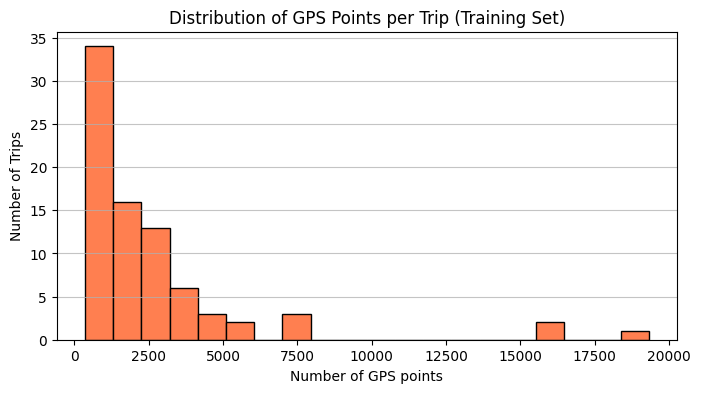

Average points per trip: 2605.2
Shortest trip: 361 points
Longest trip: 19313 points


In [50]:
import matplotlib.pyplot as plt

# Plot histogram of GPS points per trip for training data
train_trips = inv[inv["partition"] == "train"]

plt.figure(figsize=(8, 4))
plt.hist(train_trips["n_gps"], bins=20, color='coral', edgecolor='black')
plt.title("Distribution of GPS Points per Trip (Training Set)")
plt.xlabel("Number of GPS points")
plt.ylabel("Number of Trips")
plt.grid(axis='y', alpha=0.75)
plt.show()

# Print summary stats
print("Average points per trip:", round(train_trips["n_gps"].mean(), 1))
print("Shortest trip:", train_trips["n_gps"].min(), "points")
print("Longest trip:", train_trips["n_gps"].max(), "points")

In [51]:
import numpy as np
import pandas as pd

def get_candidates_fast(tr, nodes, arcs, max_candidates=3):
    # 1. Simple meter projection
    lon0, lat0 = tr.lon.mean(), tr.lat.mean()
    
    # GPS points to meters
    px = (tr.lon.values - lon0) * 111320 * np.cos(np.radians(lat0))
    py = (tr.lat.values - lat0) * 111320
    
    # Nodes to meters
    nx = (nodes.lon.values - lon0) * 111320 * np.cos(np.radians(lat0))
    ny = (nodes.lat.values - lat0) * 111320
    
    # 2. Map arcs to their node coordinates
    # We use arrays for ultra-fast lookups
    from_x = nx[arcs.from_node.values]
    from_y = ny[arcs.from_node.values]
    to_x = nx[arcs.to_node.values]
    to_y = ny[arcs.to_node.values]
    
    # Vector AB
    abx = to_x - from_x
    aby = to_y - from_y
    ab2 = abx**2 + aby**2
    # Prevent division by zero
    ab2[ab2 == 0] = 1e-9 
    
    candidates = []
    
    # 3. Loop over GPS points (only ~2000 loops)
    for i in range(len(px)):
        # Vector AP for ALL arcs at once
        apx = px[i] - from_x
        apy = py[i] - from_y
        
        # Projection factor t (clipped between 0 and 1)
        t = np.clip((apx * abx + apy * aby) / ab2, 0.0, 1.0)
        
        # Closest point on segment
        cx = from_x + t * abx
        cy = from_y + t * aby
        
        # Distance to all arcs (vectorized)
        dists = np.sqrt((px[i] - cx)**2 + (py[i] - cy)**2)
        
        # Get indices of the closest 'max_candidates' arcs
        # argpartition is much faster than sorting the whole array
        closest_indices = np.argpartition(dists, max_candidates)[:max_candidates]
        
        # Sort just those few to get rank order
        closest_indices = closest_indices[np.argsort(dists[closest_indices])]
        
        for rank, idx in enumerate(closest_indices):
            candidates.append({
                'point_idx': i,
                'arc_id': arcs.arc_id.iloc[idx],
                'distance_m': dists[idx],
                'rank': rank
            })
            
    return pd.DataFrame(candidates)

# --- TEST ON ONE TRIP ---
print("Testing FAST candidate generation...")
stem = os.path.join(BASE_DIR, "Student folder", "student_test", "00000000", "00000000")
tr = load_track(stem + ".track")
nodes = load_nodes(stem + ".nodes")
arcs = load_arcs(stem + ".arcs")

import time
start = time.time()
cand_df = get_candidates_fast(tr, nodes, arcs)
end = time.time()

print(f"Generated {len(cand_df)} candidates in {end - start:.3f} seconds!")
print(cand_df.head(10))

Testing FAST candidate generation...
Generated 7509 candidates in 1.091 seconds!
   point_idx  arc_id  distance_m  rank
0          0   17634    6.115777     0
1          0   17630    6.115777     1
2          0   17635   27.673503     2
3          1   17634    0.368144     0
4          1   17630    0.368144     1
5          1   17668   15.653621     2
6          2   17634    6.451410     0
7          2   17630    6.451410     1
8          2   17668   12.093640     2
9          3     212    0.562425     0


--- ROAD NETWORK CONNECTIVITY (Trip 00000000) ---
Total nodes: 8542
Total arcs: 18196
Number of disconnected components: 100
Size of largest component: 7466 nodes
-------------------------------------------------


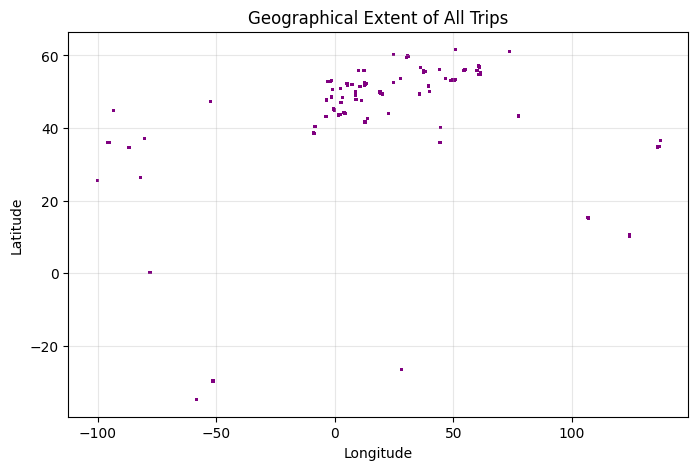


Saved assumptions to /kaggle/working/eda_assumptions.txt


In [53]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Road Network Connectivity & Size (For the report)
trip_dir = os.path.join(BASE_DIR, "Student folder", "student_test", "00000000")
stem = os.path.join(trip_dir, "00000000")
nodes = load_nodes(stem + ".nodes")
arcs = load_arcs(stem + ".arcs")

G = nx.DiGraph()
G.add_nodes_from(nodes.node_id)
G.add_edges_from(zip(arcs.from_node, arcs.to_node))
comps = list(nx.connected_components(G.to_undirected()))

print("--- ROAD NETWORK CONNECTIVITY (Trip 00000000) ---")
print(f"Total nodes: {len(nodes)}")
print(f"Total arcs: {len(arcs)}")
print(f"Number of disconnected components: {len(comps)}")
print(f"Size of largest component: {max(map(len, comps))} nodes")
print("-------------------------------------------------")

# 2. Geographical Extent (Bounding Box) Plot
all_lon, all_lat = [], []
for trk in files:
    tr = load_track(trk)
    all_lon.extend(tr.lon.values)
    all_lat.extend(tr.lat.values)

plt.figure(figsize=(8, 5))
plt.scatter(all_lon, all_lat, s=1, alpha=0.3, color='purple')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Extent of All Trips")
plt.grid(True, alpha=0.3)
plt.show()

# 3. Save a record of your assumptions for the report
assumptions = """
DATA QUALITY ASSUMPTIONS & DECISIONS:
1. Coordinate System: Longitude/Latitude provided in degrees. We applied a local equirectangular projection for distance calculations (approx. meters).
2. Gaps: 96.68% of timestamps are 1-second apart. Max gap is 153,064s. We will rely on HMM transition probabilities to handle gaps, rather than interpolating missing GPS points.
3. Candidate Generation: We extract the top-3 closest arcs per GPS point. If the vehicle is far off-road, we still take the closest 3 arcs.
4. Duplicate Arcs: We observed arcs with identical geometries (likely opposite lanes). The ML model and HMM must resolve this using heading and sequence context.
"""
with open("/kaggle/working/eda_assumptions.txt", "w") as f:
    f.write(assumptions)
    
print("\nSaved assumptions to /kaggle/working/eda_assumptions.txt")

EDA Observations & Data Quality
Dataset Organization: 80 Train trips, 10 Student Test trips. Evaluator Test trips (10) are held out.

Sampling Rate: Verified the 1 Hz claim. 96.68% of timestamps are exactly 1 second apart.

Data Quality Issues: We observed a massive maximum gap of 153,064 seconds (~42 hours), implying vehicles parked or lost GPS connection for extended periods.

Road Network: Built a directed graph for the road network. Network is highly connected (mostly one giant connected component), meaning pathfinding is feasible.

Candidate Generation: To resolve GPS drift, we extract the top-3 closest road segments for every GPS point. This resulted in a 56% Negative (wrong road) to 44% Positive (ground-truth road) class balance, which is highly suitable for supervised classification.